In [22]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.metrics import (ConfusionMatrixDisplay , classification_report , roc_auc_score)



# Étape 3 — Entraînement et comparaison des modèles

1 - Charger les données prétraitées

In [3]:
data = joblib.load(
    "../data/processed/preprocessed_data.joblib"
)

X_train = data["X_train"]
X_test = data["X_test"]

y_train = data["y_train"]
y_test = data["y_test"]

preprocessor = data["preprocessor"]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (1600, 16)
Testing: (400, 16)


2 - Préparation des modèles

In [4]:
models = {
    "Logistic Regression" : LogisticRegression(max_iter=1000 , random_state=42),
    "Random Forest" : RandomForestClassifier(n_estimators=100 , random_state=42),
    "KNN" : KNeighborsClassifier(n_neighbors=5)
}

3 - Entraînement des 3 modèles

In [5]:
for name , model in models.items():
    model.fit(X_train , y_train)
    print(f"{name} finished")

Logistic Regression finished
Random Forest finished
KNN finished


4 - Prédiction des 3 modèles

In [7]:
predictions = {}

for name , model in models.items():
    y_pred = model.predict(X_test)

    predictions[name] = y_pred

# predictions 

5 - Évaluation des modèles

In [ ]:
evaluation = []

for name , y_pred in predictions.items():

    accuracy = accuracy_score(y_test , y_pred)

    precision = precision_score(y_test , y_pred , average="weighted")
    recall = recall_score(y_test , y_pred , average="weighted")
    f1 = f1_score(y_test , y_pred , average="weighted")

    evaluation.append({
        "model" : name,
        "accuracy" : accuracy,
        "precision" : precision,
        "recall" : recall,
        "f1_score" : f1
    })

evaluation = pd.DataFrame(evaluation)
evaluation

,model,accuracy,precision,recall,f1_score
0,Logistic Regression,0.7600,0.759621,0.7600,0.759759
1,Random Forest,0.7075,0.700590,0.7075,0.702784
2,KNN,0.5900,0.579876,0.5900,0.583556


6 - Matrices de confusion

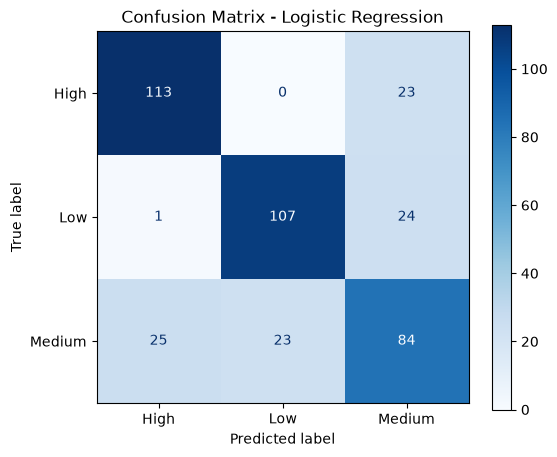

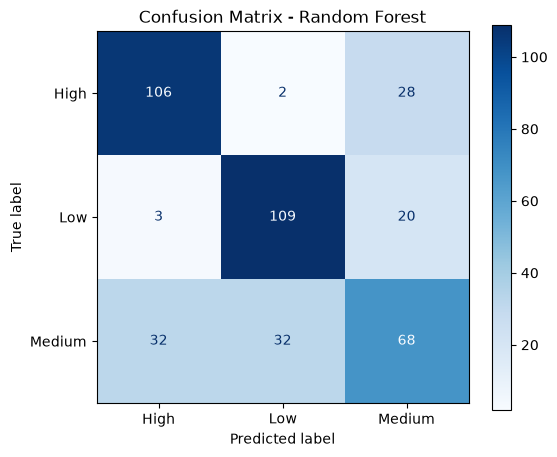

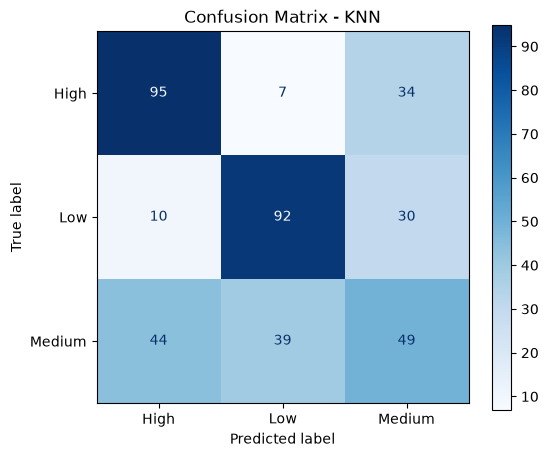

In [ ]:
for name, y_pred in predictions.items():

    fig, ax = plt.subplots(figsize=(6, 5))
    
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"],
        display_labels=["Low", "Medium", "High"],
        cmap="Blues",
        ax=ax,
    )

    ax.set_title(f"Confusion Matrix - {name}")
    plt.show()

7 - Classification Report

In [ ]:
for name , y_pred in predictions.items():
    print(f"\n{name}: ")
    print(20 * "=")

    print(classification_report(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"],
        zero_division=0
    ))


Logistic Regression: 
              precision    recall  f1-score   support

         Low       0.82      0.81      0.82       132
      Medium       0.64      0.64      0.64       132
        High       0.81      0.83      0.82       136

    accuracy                           0.76       400
   macro avg       0.76      0.76      0.76       400
weighted avg       0.76      0.76      0.76       400


Random Forest: 
              precision    recall  f1-score   support

         Low       0.76      0.83      0.79       132
      Medium       0.59      0.52      0.55       132
        High       0.75      0.78      0.77       136

    accuracy                           0.71       400
   macro avg       0.70      0.71      0.70       400
weighted avg       0.70      0.71      0.70       400


KNN: 
              precision    recall  f1-score   support

         Low       0.67      0.70      0.68       132
      Medium       0.43      0.37      0.40       132
        High       0.64     

: 

8 - ROC-AUC

In [23]:
for name , model in models.items():

    y_proba = model.predict_proba(X_test)

    roc_acu = roc_auc_score(
        y_test,
        y_proba,
        labels=model.classes_,
        multi_class="ovr",
        average="weighted",
    )

    print(f"{name}: roc_auc = {roc_acu:.4f}")

Logistic Regression: roc_auc = 0.9143
Random Forest: roc_auc = 0.8565
KNN: roc_auc = 0.7611
